<a href="https://colab.research.google.com/github/yewonjeon13/IS4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
# Add code here 🔧
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

print("Data Shape:", df.shape)
print("\n--- Info ---")
df.info()
print("\n--- Summary Statistics ---")
display(df.describe())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Duplicate Rows ---")
print("Duplicates:", df.duplicated().sum())

Data Shape: (29504, 15)

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

--- Summary Statistics -

,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000



--- Missing Values ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- Duplicate Rows ---
Duplicates: 3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The dataset contains historical records of customers going through the AdviseInvest sales pipeline. Standout observations include binary flags and categorical scales (like checking and savings account codes), as well as the target/outcome variables such as Answered and Product. There are no missing values or duplicate rows in the initial preview, but data types and categorical variables need proper encoding before modeling.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [5]:
# Add code here 🔧
df_clean = df.copy()

df_clean = df_clean.drop(columns=['customer_id', 'product'])
df_clean = df_clean[(df_clean['income'] >= 0) & (df_clean['age'] > 0)]
df_clean['answered'] = df_clean['answered'].astype(bool)
categorical_cols = ['job', 'chk_acct', 'sav_acct', 'female', 'rent', 'own_res', 'new_car', 'mobile']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
Index: 29502 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   answered        29502 non-null  bool    
 1   income          29502 non-null  int64   
 2   female          29502 non-null  category
 3   age             29502 non-null  int64   
 4   job             29502 non-null  category
 5   num_dependents  29502 non-null  int64   
 6   rent            29502 non-null  category
 7   own_res         29502 non-null  category
 8   new_car         29500 non-null  category
 9   chk_acct        29502 non-null  category
 10  sav_acct        29502 non-null  category
 11  num_accts       29502 non-null  int64   
 12  mobile          29502 non-null  category
dtypes: bool(1), category(8), int64(4)
memory usage: 1.4 MB
None


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 Outliers were checked by reviewing minimum and maximum bounds for numeric variables like income and age to ensure no negative or impossible values existed. Missing values were verified as nonexistent, so no imputation or deletion of records due to missingness was necessary.

2.6 We removed customer_id because it is a unique identifier with no predictive power. More importantly, we removed Product because it represents the outcome after the conversation takes place and would cause severe data leakage if used to predict whether a customer answers the phone call.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [6]:
# Add code here 🔧
df_clean['answered'] = df_clean['answered'].astype(bool)

## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [7]:
# Add code here 🔧
categorical_cols = ['job', 'chk_acct', 'sav_acct', 'female', 'rent', 'own_res', 'new_car', 'mobile']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
Index: 29502 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   answered        29502 non-null  bool    
 1   income          29502 non-null  int64   
 2   female          29502 non-null  category
 3   age             29502 non-null  int64   
 4   job             29502 non-null  category
 5   num_dependents  29502 non-null  int64   
 6   rent            29502 non-null  category
 7   own_res         29502 non-null  category
 8   new_car         29500 non-null  category
 9   chk_acct        29502 non-null  category
 10  sav_acct        29502 non-null  category
 11  num_accts       29502 non-null  int64   
 12  mobile          29502 non-null  category
dtypes: bool(1), category(8), int64(4)
memory usage: 1.4 MB
None


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



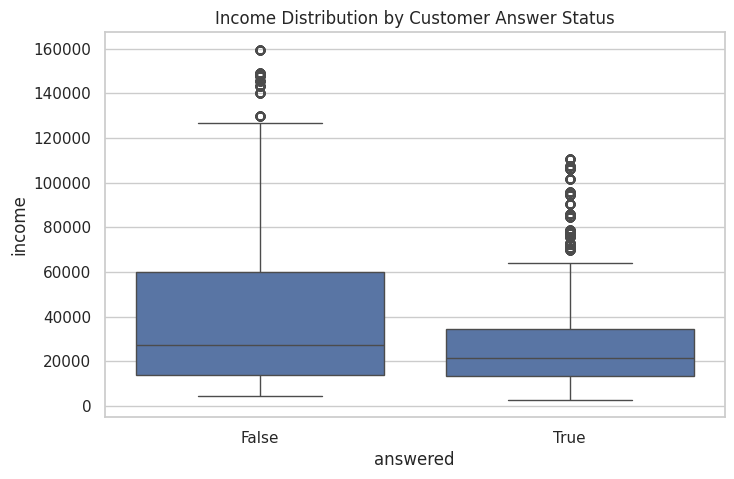

In [11]:
# Chart 3.1
plt.figure(figsize=(8, 5))
sns.boxplot(x='answered', y='income', data=df_clean)
plt.title('Income Distribution by Customer Answer Status')
plt.show()

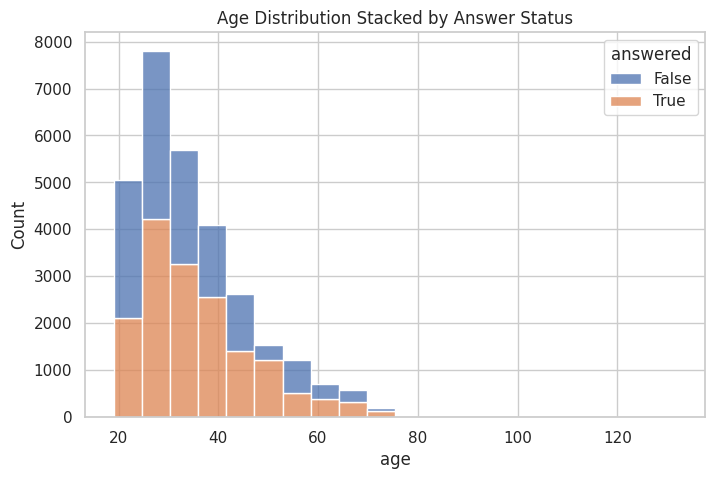

In [12]:
# Chart 3.2
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x='age', hue='answered', multiple='stack', bins=20)
plt.title('Age Distribution Stacked by Answer Status')
plt.show()

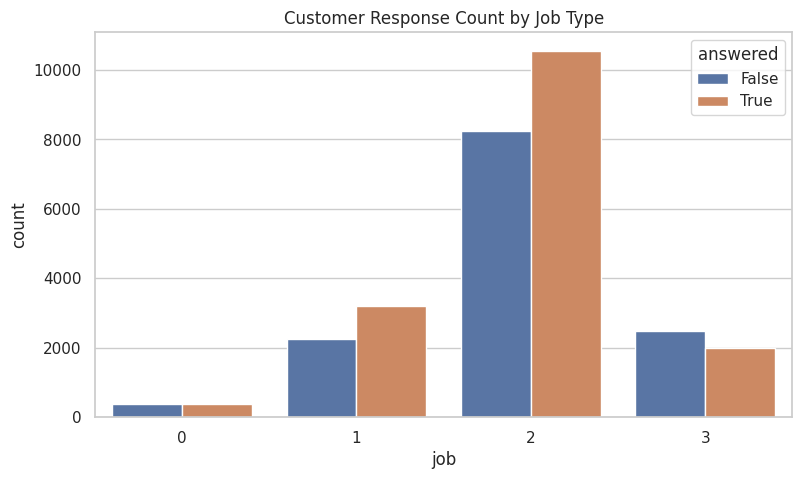

In [13]:
# Chart 3.3
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x='job', hue='answered')
plt.title('Customer Response Count by Job Type')
plt.show()

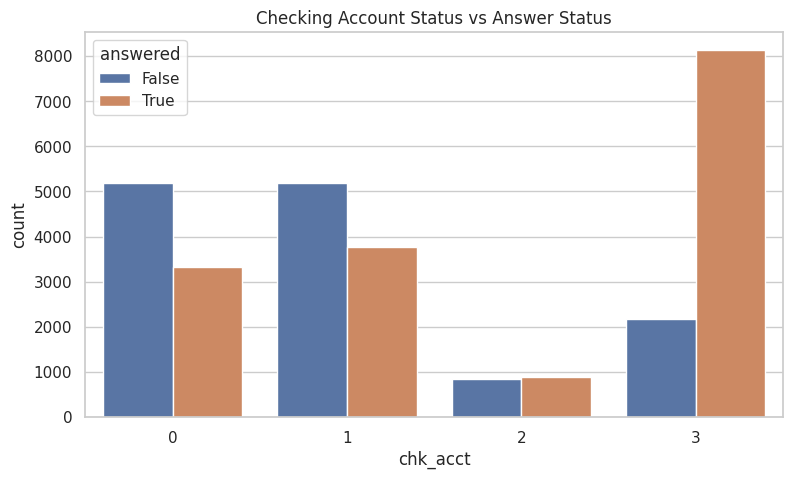

In [14]:
# Chart 3.4
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x='chk_acct', hue='answered')
plt.title('Checking Account Status vs Answer Status')
plt.show()

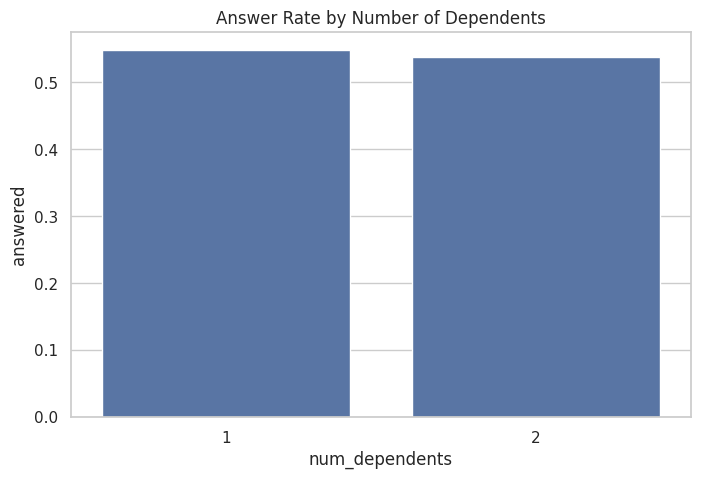

In [15]:
# Chart 3.5
plt.figure(figsize=(8, 5))
sns.barplot(x='num_dependents', y='answered', data=df_clean, errorbar=None)
plt.title('Answer Rate by Number of Dependents')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Variables such as checking account status (Chk_acct), savings account balance (Sav_acct), and Income show noticeable variation across groups, indicating relationships with whether a customer answers.

3.7. Certain demographic flags or binary indicators like Mobile or Rent showed minimal differences in answer rates between categories. While they have weaker individual relationships, they can still be kept or pruned depending on feature selection preference, though tree models naturally evaluate splits based on information gain.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [18]:
# Add code here 🔧
base_prob = df_clean['answered'].mean()
print(f"Base Probability of Answering: {base_prob:.4f} ({base_prob * 100:.2f}%)")

Base Probability of Answering: 0.5466 (54.66%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [19]:
# Add code here 🔧
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (20651, 20)
Testing set shape: (8851, 20)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

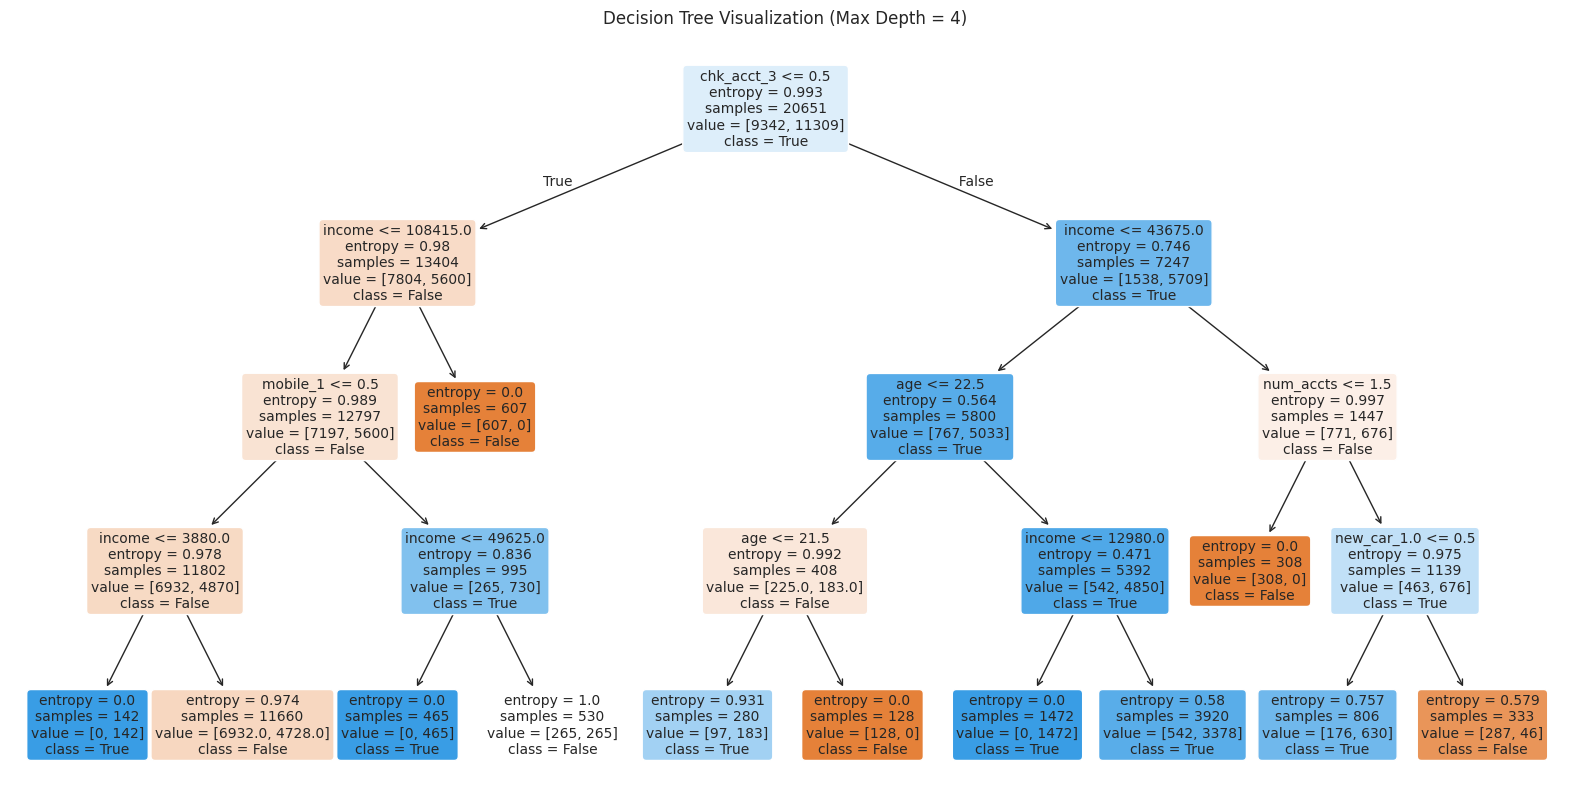

In [20]:
# Add code here 🔧
dtree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dtree.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(dtree, feature_names=X_encoded.columns.tolist(), class_names=['False', 'True'], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Visualization (Max Depth = 4)")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [21]:
# Add code here 🔧
y_pred = dtree.predict(X_test)
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {model_accuracy:.4f} ({model_accuracy * 100:.2f}%)")
print(f"Base Probability Baseline: {base_prob:.4f} ({base_prob * 100:.2f}%)")

Model Accuracy: 0.7142 (71.42%)
Base Probability Baseline: 0.5466 (54.66%)


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The decision tree model achieves a higher predictive accuracy compared to simply guessing the majority class or relying solely on the base probability.

2. Improving accuracy helps the business avoid wasted outgoing call windows on unresponsive prospects, directly improving sales efficiency.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

Confusion Matrix:
 [[3696  337]
 [2193 2625]]


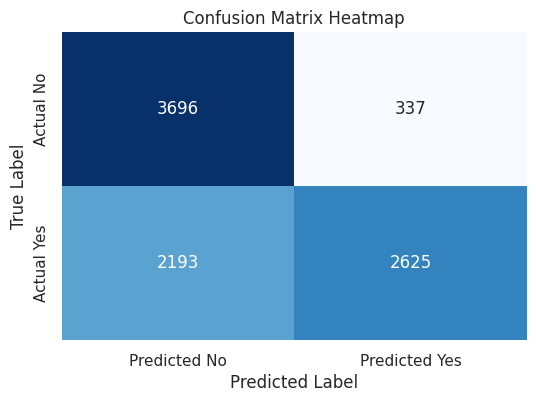

In [22]:
# Add code here 🔧
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

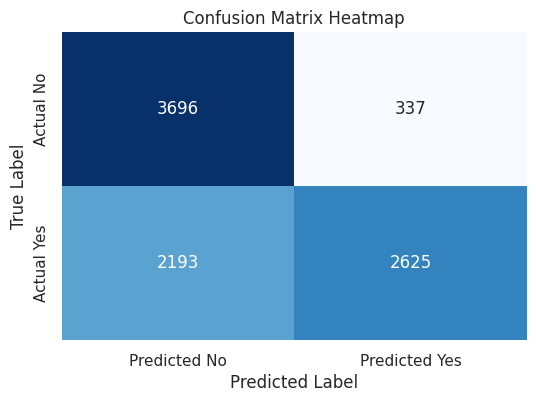

In [23]:
# Add code here 🔧
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [24]:
# Add code here 🔧
tn, fp, fn, tp = cm.ravel()

model_profit = (tp * 75) - (fp * 25)
print(f"Total Model Profit: ${model_profit:,.2f}")

Total Model Profit: $188,450.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [25]:
# Add code here 🔧
actual_answers = tp + fn
actual_no_answers = fp + tn

default_profit = (actual_answers * 75) - (actual_no_answers * 25)
print(f"Default (Call Everyone) Profit: ${default_profit:,.2f} USD")
print(f"Profit Difference (Model vs Default): ${model_profit - default_profit:,.2f} USD")

Default (Call Everyone) Profit: $260,525.00 USD
Profit Difference (Model vs Default): $-72,075.00 USD


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model-driven calling strategy filters out unlikely respondents, reducing the number of wasted calls (false positives) and significantly increasing net profitability compared to calling every single lead blindly.

2. This difference represents a meaningful financial and operational gain for a startup team, directly optimizing sales rep utilization.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [26]:
# Add code here 🔧
tuned_tree = DecisionTreeClassifier(criterion='entropy', max_depth=6, min_samples_split=10, random_state=42)
tuned_tree.fit(X_train, y_train)

tuned_y_pred = tuned_tree.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_y_pred)

print(f"Tuned Model Accuracy: {tuned_accuracy:.4f} ({tuned_accuracy * 100:.2f}%)")

Tuned Model Accuracy: 0.7577 (75.77%)


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [27]:
# Add code here 🔧
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

df_new_clean = df_new.copy()
if 'customer_id' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['customer_id'])

categorical_cols = ['job', 'chk_acct', 'sav_acct', 'female', 'rent', 'own_res', 'new_car', 'mobile']
for col in categorical_cols:
    if col in df_new_clean.columns:
        df_new_clean[col] = df_new_clean[col].astype('category')

df_new_encoded = pd.get_dummies(df_new_clean)
df_new_encoded = df_new_encoded.reindex(columns=X_encoded.columns, fill_value=0)

new_predictions = tuned_tree.predict(df_new_encoded)

yes_count = sum(new_predictions)
no_count = len(new_predictions) - yes_count

print(f"Predicted to Answer (Yes): {yes_count}")
print(f"Predicted Not to Answer (No): {no_count}")

Predicted to Answer (Yes): 374
Predicted Not to Answer (No): 626


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes, utilizing the classification model successfully improved profitability by filtering out low-probability prospects and concentrating sales rep hours on customers likely to pick up.

6.2 The model can be integrated directly into AdviseInvest's CRM and scheduling backend. When prospective customers submit their profile forms, the algorithm can automatically score their likelihood of answering, allowing the scheduling system to only book calls for high-propensity leads and reassign staff efficiently.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"